# CHAZ intensity

The [tracks notebook](tracks.ipynb) found that our ERA5 run reaches the US coast about as often as
the CHAZ team's, and that the two differ in how long their intensity members last. This notebook
looks at the intensity model around the globe and tests the options of `chaz` that change it:

- `--land fine` reads the land term at the storm's position on the 1/12° land mask rather than in
  the 2° cell it is in (section 2)
- `--intensity refit` refits the water and land regressions on our ERA5 environment along the
  observed tracks of 1981–2012 (sections 3 and 4)
- `--intensity refit-pi` and `--intensity refit-basin` also draw the random error from observed
  steps with similar ring PI, and then from steps in the same basin as well (section 4)

Every run covers 1981–2019 with 10 track realizations of 40 intensity members. They use the same
random seeds, so they have the same tracks and differ only in intensity. The refit options read land
as `--land fine` does, since they are fit on it. 'shipped' is the run with the public code's
settings, the one the tracks notebook calls 'ours'.

`ocr.risks.hurricane.validate` compares each set with IBTrACS by the same rules. IBTrACS's wind is
USA_WIND, or where USA_WIND is missing, the WMO agency's wind converted to a 1-minute wind as
CLIMADA converts it (`landfall.observed_records`). USA_WIND in the Southern Hemisphere and western
Pacific comes mostly from JTWC, which often stops following a storm around extratropical transition; the regional
agencies keep following it, and their records count at any stage of the storm, as HURDAT's do in
the North Atlantic. The rules:

- landfalls by country: each storm's first crossing from sea onto a country's land, on the
  Natural Earth 1:10m countries at 1/12°, timed to 10 minutes and counted at the member's wind
  interpolated to that time. This is the first-crossing rule of Emanuel (2025), adapted as
  [landfall.ipynb](landfall.ipynb) describes
- time at 64 and 96 kt: 6-hourly points over sea in the regions of `validate.REGIONS` and, for
  North Atlantic storms, in six North Atlantic regions
- storms first reaching 34 kt, by where they reach it
- US landfalls on the Atlantic and Gulf coasts, by the same rule

Section 5 tests the options with the measures of Lee et al. (2018), on all of 1981–2019 and on
years the fits did not see, with landfalls also counted at each storm's strongest crossing and its
last offshore wind, the sensitivity test of landfall.ipynb.

Rates are per year, and CHAZ's per intensity member. North Atlantic quantities (US landfalls and
time in the North Atlantic regions) are scaled so that each set's North Atlantic storm count
matches the observed one; the rest are not scaled. Section 4 gives the North Atlantic ratios
without the scaling as well. A storm belongs to the year of its first record.

All the sets make about as many storms as observed. The refit options bring more members to
34 kt: about 94 a year, against 85.0 with the shipped model and 88.6 observed. Read with
`observed_data.nc`, the normalization the shipped coefficients were fit with (section 3), the shipped model
brings 95.7 a year to 34 kt.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from ocr.risks.hurricane import chaz, meanstd, refit, skill, store, validate

RUN = 'TCGI_CRH_PI'
FINE = f'{RUN}-land-fine'
SOURCES = {
    'CHAZ team': 'chaz-team',
    'shipped': RUN,
    'fine land': FINE,
    'refit': f'{FINE}-intensity-refit',
    'refit-pi': f'{FINE}-intensity-refit-pi',
    'refit-basin': f'{FINE}-intensity-refit-basin',
    'refit, fit 1981-1999': f'{FINE}-intensity-refit-fit-1981-1999',
    'shipped, port normalization': f'{RUN}-normalization-port',
    'shipped, env normalization': f'{RUN}-normalization-env',
    'shipped, training normalization': f'{RUN}-normalization-training',
    'refit-basin, fit 1981-1999': f'{FINE}-intensity-refit-basin-fit-1981-1999',
}
COLORS = {
    'CHAZ team': '#eb6834',
    'shipped': '#2a78d6',
    'fine land': '#8a5cc7',
    'refit': '#9c9a92',
    'refit-pi': '#e0a526',
    'refit-basin': '#1baf7a',
    'refit, fit 1981-1999': '#6b6a64',
    'shipped, port normalization': '#6da7ec',
    'shipped, env normalization': '#184f95',
    'shipped, training normalization': '#a3c8f2',
    'refit-basin, fit 1981-1999': '#0e6b4a',
}
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
tables = {'IBTrACS': validate.load('ibtracs')} | {k: validate.load(v) for k, v in SOURCES.items()}
realizations = {name: validate.load_realizations(run) for name, run in SOURCES.items()}
YEARS = range(1981, 2020)
rates = validate.metrics(tables, YEARS)  # per year, 1981-2019


def vs_observed(rows, sources=None, digits=2):
    """IBTrACS per year, and each source over IBTrACS, for the rows IBTrACS has."""
    table = rates.loc[rows, ['IBTrACS', *(sources or SOURCES)]]
    table = table[table['IBTrACS'] > 0]
    ratio = table.drop(columns='IBTrACS').div(table['IBTrACS'], axis=0)
    observed = table[['IBTrACS']].rename(columns={'IBTrACS': 'IBTrACS per yr'})
    return pd.concat([observed, ratio], axis=1)


pd.DataFrame(
    {
        name: {
            'members per year': table['members'].mean(),
            'storms reaching 34 kt per member-year': table['TS formed global'].sum()
            / table['members'].sum(),
            'NA tropical storms per member-year': table['NA TS'].sum() / table['members'].sum(),
        }
        for name, table in tables.items()
    }
).T.style.format('{:.1f}')

,members per year,storms reaching 34 kt per member-year,NA tropical storms per member-year
IBTrACS,1.0,88.6,13.4
CHAZ team,400.0,88.0,12.7
shipped,400.0,85.0,13.2
fine land,400.0,85.7,13.4
refit,400.0,93.9,12.7
refit-pi,400.0,93.8,12.5
refit-basin,400.0,94.6,14.1
"refit, fit 1981-1999",400.0,91.1,12.4
"shipped, port normalization",400.0,93.3,12.8
"shipped, env normalization",400.0,93.4,13.5


## 1. The shipped intensity model around the globe

With the shipped coefficients, our run spends too little time at hurricane and major strength
in the Philippine Sea, the North Atlantic tropics and the Caribbean, and far too much at high
latitudes. At 96 kt it has 0.27 of the observed time in the
Philippine Sea, 0.56 in the North Atlantic tropics and 0.35 in the Caribbean. North of 35°N in the
western Pacific it has 169 times the observed time at 96 kt, and north of 45°N in the North
Atlantic 65 times. The CHAZ team's set has the same pattern (0.40, 0.63 and 0.37; 76 and 16
times). Observed storms seldom stay that strong that far poleward, so the high-latitude ratios
rest on small observed numbers, and the counts tested in section 5 leave those regions out.

In [2]:
regions = [
    f'time {region} >= {threshold}' for threshold in (64, 96) for region in validate.REGIONS
] + [
    f'NA time >= {threshold}: {region}' for threshold in (64, 96) for region in validate.NA_REGIONS
]
vs_observed(regions, ['CHAZ team', 'shipped']).style.format('{:.2f}').set_caption(
    "6-hourly points over sea at 64 and 96 kt, 1981-2019; the 'NA time' rows, North Atlantic "
    'storms only, scaled to the observed North Atlantic storm count; the others per year'
)

,IBTrACS per yr,CHAZ team,shipped
time WP Philippine Sea >= 64,133.72,0.57,0.37
time WP South China Sea >= 64,51.23,0.48,0.57
time WP East China Sea/Japan >= 64,44.90,0.68,0.58
time WP north of 35N >= 64,4.00,4.29,7.41
time EP main >= 64,130.13,0.92,0.87
time EP north of 25N >= 64,0.87,4.83,12.69
time NI Bay of Bengal >= 64,8.15,0.98,1.53
time NI Arabian Sea >= 64,5.41,0.55,0.93
time SI west >= 64,78.33,1.04,0.80
time AU >= 64,43.72,1.16,1.35


At 64 kt the shipped run makes 0.31 of the observed Philippine landfalls and 0.39 of
Taiwan's, and 1.7 times Australia's. Section 2 has US landfalls.

In [3]:
countries = [
    f'landfall {country} >= {threshold}'
    for threshold in (34, 64)
    for country in validate.COUNTRIES
    if country != 'USA'
]
vs_observed(countries, ['CHAZ team', 'shipped']).style.format('{:.2f}').set_caption(
    'Landfalls by country per year, each storm at its first crossing onto the country'
)

,IBTrACS per yr,CHAZ team,shipped
landfall MEX >= 34,3.00,1.14,1.39
landfall CUB >= 34,0.69,0.79,1.09
landfall PHL >= 34,4.13,0.68,0.61
landfall CHN >= 34,5.44,0.82,0.81
landfall TWN >= 34,1.77,0.75,0.65
landfall JPN >= 34,3.69,1.06,1.00
landfall KOR >= 34,0.74,1.19,1.37
landfall VNM >= 34,2.69,0.77,0.99
landfall IND >= 34,1.82,0.51,0.76
landfall BGD >= 34,0.54,0.43,0.74


## 2. Land at the storm's position

The public code reads the land term from the 2° land mask cell the storm is in, so a storm over
open water in a cell the mask counts as land weakens as if it were over land. `--land fine` reads
the land term at the storm's own position on the tutorial's 1/12° mask.

In the North Atlantic this adds hurricane time in the Gulf (9.4 to 10.2 points a year, against
10.3 observed) and US hurricane landfalls (0.815 to 0.846 a year, against 1.359 observed). These
are scaled to the observed North Atlantic storm count; the shipped and fine-land runs make almost
the observed count, so the scaling moves them by about 1% or less (section 4). By Lee et al.'s measures it does no
better than the shipped run (section 5). The refit options are fit on it.

The table also shows how far the shipped run is from observed US landfalls: 0.815 hurricane
landfalls a year against 1.359, and 0.111 in Georgia and the Carolinas against 0.308. The CHAZ
team's set makes fewer (0.607). Our runs also make about 0.37 landfalls a year on the US Pacific
coast, against 0.066 in the CHAZ team's set; IBTrACS has no landfalls there at 34 kt or more over
these years.

In [4]:
na_rows = (
    ['NA TS storms/yr', 'NA share peak >= 64 kt', 'NA share peak >= 96 kt']
    + [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)]
    + [f'{coast} landfalls >= 64 kt' for coast in ('TX-AL', 'FL', 'GA-Car', 'VA-ME')]
    + ['Pacific coast landfalls >= 34 kt']
    + [
        f'NA time >= {threshold}: {region}'
        for threshold in (64, 96)
        for region in validate.NA_REGIONS
    ]
)
na_table = rates.loc[na_rows, ['IBTrACS', 'CHAZ team', 'shipped', 'fine land']]
na_table.style.format('{:.3f}').set_caption(
    'North Atlantic per year, 1981-2019; landfalls and time over sea scaled to the observed '
    'North Atlantic storm count (the Pacific coast row too: IBTrACS has none there)'
)

,IBTrACS,CHAZ team,shipped,fine land
NA TS storms/yr,13.385,12.701,13.220,13.396
NA share peak >= 64 kt,0.506,0.449,0.460,0.466
NA share peak >= 96 kt,0.207,0.200,0.199,0.204
Atl+Gulf landfalls >= 34 kt,3.077,2.208,2.741,2.764
Atl+Gulf landfalls >= 64 kt,1.359,0.607,0.815,0.846
Atl+Gulf landfalls >= 96 kt,0.256,0.116,0.171,0.174
TX-AL landfalls >= 64 kt,0.564,0.236,0.369,0.381
FL landfalls >= 64 kt,0.410,0.213,0.289,0.300
GA-Car landfalls >= 64 kt,0.308,0.116,0.111,0.115
VA-ME landfalls >= 64 kt,0.077,0.042,0.046,0.050


## 3. The shipped regression's response to PI

CHAZ standardizes each predictor with a mean and standard deviation from `coefficient_meanstd.nc`
before applying the regression's coefficients. Fitting the water regression as the public code's
regression script does (`CHAZvBeta/tools/regression4.py`) on the tutorial's own observed-track file (`bt_global_predictors.nc`) gives back the shipped
coefficients to within 0.04. But in that sample the PI-minus-wind predictor (`dPIwspd`) has a mean
of 85 kt and a standard deviation of 44 kt, and the shipped normalization has 30 and 70. The
shipped coefficients match a fit on that sample but are read with a different standardization.
Over water they are also within 0.044 of the published coefficients of Lee et al. (2016, Table 2),
fit on ERA-Interim along the observed tracks of 1981–1999 (second table).

In [5]:
tutorial = refit.fit(refit.tutorial_env())
era5_env = refit.era5_env()
era5 = refit.fit(era5_env)
shipped = refit.shipped()
names = ['const', *meanstd.WATER]
pd.DataFrame(
    {
        'shipped': shipped['w']['params'],
        'refit on the tutorial file': tutorial['w']['params'],
        'mean, shipped normalization': shipped['w']['meanX'],
        'mean, tutorial file sample': tutorial['w']['meanX'],
        'sd, shipped normalization': shipped['w']['stdX'],
        'sd, tutorial file sample': tutorial['w']['stdX'],
    },
    index=names,
).style.format('{:.3f}').set_caption(
    'Water regression: standardized coefficients and the normalization each is read with'
)

,shipped,refit on the tutorial file,"mean, shipped normalization","mean, tutorial file sample","sd, shipped normalization","sd, tutorial file sample"
const,0.000,-0.000,0.000,0.000,0.000,0.000
StormMwspd,-0.155,-0.142,50.700,48.728,25.851,28.272
dVdt,0.484,0.459,1.437,1.621,9.730,8.863
trSpeed,0.051,0.046,4.899,3.996,2.851,2.327
dPIwspd,0.326,0.331,30.157,85.013,70.183,43.759
SHRD,-0.101,-0.102,8.791,8.378,5.948,5.757
rhMean,0.084,0.082,59.347,60.020,10.643,8.994
dPIwspd2,0.211,0.195,5835.035,9141.976,5217.420,6329.424
dPIwspd3,-0.454,-0.417,402117.096,1037520.869,781400.051,907492.061
dVdt2,0.032,0.012,96.740,81.184,223.298,186.872


In [6]:
# Lee et al. (2016), Table 2, MLR3 over the ocean, in the order of meanstd.WATER
LEE_2016 = [-0.15, 0.49, 0.05, 0.31, -0.10, 0.08, 0.18, -0.41, 0.03]
shipped_water = shipped['w']['params'][1:]
pd.DataFrame(
    {'shipped (result_w.nc)': shipped_water, 'Lee et al. (2016)': LEE_2016}, index=meanstd.WATER
).assign(difference=lambda frame: frame.iloc[:, 0] - frame.iloc[:, 1]).style.format('{:+.3f}')

,shipped (result_w.nc),Lee et al. (2016),difference
StormMwspd,-0.155,-0.150,-0.005
dVdt,+0.484,+0.490,-0.006
trSpeed,+0.051,+0.050,+0.001
dPIwspd,+0.326,+0.310,+0.016
SHRD,-0.101,-0.100,-0.001
rhMean,+0.084,+0.080,+0.004
dPIwspd2,+0.211,+0.180,+0.031
dPIwspd3,-0.454,-0.410,-0.044
dVdt2,+0.032,+0.030,+0.002


**Where the normalizations come from.** The tutorial has two normalization files. CHAZ applies
`coefficient_meanstd.nc`. It also reads `observed_data.nc`, which it does not use. Every entry of
`observed_data.nc` is within 1.4% of the 1981–1999 sample of the tutorial track file (first
table): `dPIwspd` has a mean of 85.40 kt and a standard deviation of 43.99 kt, against 85.46 and
43.77. Those are the fit years of Lee et al. (2016), so `observed_data.nc` is most likely the
normalization the shipped coefficients were fit with.

`coefficient_meanstd.nc` matches no sample of the track file, even in the entries that depend only
on the tracks. Storm wind has a mean of 50.70 kt against 48.46 to 48.73 in those samples. Its
translation speed is close to the speed the public code's `getMeanStd.py` recomputes from the
tracks, from each point to the next (second table). It is not close to the speed stored in the
track file, which the other samples use. `getMeanStd.py` writes `coefficient_meanstd.nc` for a
forcing, from that forcing's fields along the observed tracks of 1981–2012, and its input files are
named by a CMIP6 member (`r1i1p1f1`). So the tutorial's copy is most likely that script's output for a forcing we
cannot identify, whose ring PI along the tracks averages 80.86 kt. Our ERA5 has 125.04 kt there.
`meanstd.py` ports the script, and `--normalization port` runs the shipped coefficients with its
output on ERA5. `--normalization training` runs them with `observed_data.nc`.


In [7]:
def water(ds, suffix=''):
    return {'meanX': ds[f'meanX_w{suffix}'].values, 'stdX': ds[f'stdX_w{suffix}'].values}


bt = meanstd.observed()
stored = {key: bt[key].values.astype(float) for key in meanstd.ENV}
with (
    xr.open_dataset(chaz.static('observed_data.nc')) as observed_data,
    xr.open_dataset(store.path(meanstd.ERA5_PORT)) as era5_port,
):
    normalizations = {
        'coefficient_meanstd.nc (applied)': shipped['w'],
        'observed_data.nc (read, unused)': water(observed_data, '_obs'),
        'tutorial file sample, 1981-1999': water(meanstd.normalization(stored, (1981, 1999))),
        'tutorial file sample, 1981-2012': water(meanstd.normalization(stored)),
        'ERA5 port, 1981-2012': water(era5_port),
    }
shown = ['StormMwspd', 'dVdt', 'trSpeed', 'dPIwspd', 'SHRD', 'rhMean']
columns = {}
for name, normalization in normalizations.items():
    means = dict(zip(names, np.asarray(normalization['meanX'])))
    sds = dict(zip(names, np.asarray(normalization['stdX'])))
    columns[name] = {
        **{
            (predictor, statistic): values[predictor]
            for predictor in shown
            for statistic, values in (('mean', means), ('sd', sds))
        },
        ('ring PI = dPIwspd + StormMwspd', 'mean'): means['dPIwspd'] + means['StormMwspd'],
    }
normalization_table = pd.DataFrame(columns)
training, sample = (
    np.r_[normalizations[name]['meanX'][1:], normalizations[name]['stdX'][1:]]
    for name in ('observed_data.nc (read, unused)', 'tutorial file sample, 1981-1999')
)
print(
    'largest relative difference, observed_data.nc against the 1981-1999 sample: '
    f'{np.max(np.abs(training / sample - 1)):.3f}'
)
normalization_table.style.format('{:.2f}').set_caption(
    "Water regression normalization: the tutorial's two files, the tutorial track file's own "
    'sample and our ERA5 along the same tracks'
)

largest relative difference, observed_data.nc against the 1981-1999 sample: 0.014


In [8]:
speed = meanstd.forward_speed(
    *(bt[key].values.astype(float) for key in ('StormLon', 'StormLat', 'Time'))
)
_, _, complete = meanstd.samples(stored, meanstd.WATER, True)
starts = meanstd.steps(stored['landmaskMean'], True)[complete]
recomputed = speed[starts[:, 1] - meanstd.LEAD, starts[:, 0]]
stored_speed = bt['trSpeed'].values[starts[:, 1] - meanstd.LEAD, starts[:, 0]]
fast = recomputed > 100
pd.DataFrame(
    {
        'stored in the track file': [stored_speed.mean(), stored_speed.std(), 0],
        "getMeanStd.py's, every step": [np.nanmean(recomputed), np.nanstd(recomputed), 0],
        "getMeanStd.py's, without steps over 100 m/s": [
            np.nanmean(recomputed[~fast]),
            np.nanstd(recomputed[~fast]),
            fast.sum(),
        ],
        'coefficient_meanstd.nc': [
            shipped['w']['meanX'][names.index('trSpeed')],
            shipped['w']['stdX'][names.index('trSpeed')],
            np.nan,
        ],
    },
    index=['mean (m/s)', 'sd (m/s)', 'steps left out'],
).T.style.format('{:.2f}').set_caption(
    'Translation speed at the start of the water steps of 1981-2012 of the tutorial track file'
)

,mean (m/s),sd (m/s),steps left out
stored in the track file,4.00,2.33,0.00
"getMeanStd.py's, every step",4.81,4.90,0.00
"getMeanStd.py's, without steps over 100 m/s",4.79,2.84,2.00
coefficient_meanstd.nc,4.90,2.85,nan


With the coefficients held fixed, the normalization changes the response at both ends of PI. Take
a storm whose wind did not change over the previous 12 hours, in a mean environment. At 140 kt under a ring PI of 40 kt the
shipped files take off 1.8 kt in 12 hours. The same coefficients read with the normalization of
the sample they match take off 7.3 kt, the tutorial-file fit with its own normalization 7.8 kt, and
the ERA5 refit 16.1 kt. At the other end, the shipped files give a 60 kt storm under a ring PI of
190 kt a loss of 2.2 kt, and the same coefficients with the sample's normalization a loss of
0.1 kt. A storm far above the PI around it, as over cold water, weakens less with the shipped
files than with the normalization its coefficients match, which fits the high-latitude excess of
section 1.

ring PI (kt)                                           40    70    100  130  \
shipped                                          60   -3.0  -1.8  -0.1  1.0   
                                                 100  -4.8  -5.6  -4.7 -3.1   
                                                 140  -1.8  -6.4  -8.0 -7.6   
shipped coefficients, the sample's normalization 60   -5.3  -3.4  -1.1  0.7   
                                                 100  -8.2  -7.8  -6.1 -3.9   
                                                 140  -7.3  -9.9 -10.1 -8.8   
tutorial fit, its own normalization              60   -5.4  -3.4  -1.2  0.7   
                                                 100  -8.3  -7.8  -6.1 -3.8   
                                                 140  -7.8 -10.0 -10.0 -8.6   
ERA5 refit                                       60   -5.6  -2.8  -0.4  1.1   
                                                 100 -11.2  -8.4  -5.5 -2.9   
                                                 140 -16.1 -13.9 -11.1 -8.2   

ring PI (kt)                                          160  190  
shipped                                          60   0.7 -2.2  
                                                 100 -1.7 -1.4  
                                                 140 -6.1 -4.5  
shipped coefficients, the sample's normalization 60   1.3 -0.1  
                                                 100 -1.8 -0.8  
                                                 140 -6.7 -4.5  
tutorial fit, its own normalization              60   1.5  0.4  
                                                 100 -1.7 -0.5  
                                                 140 -6.4 -4.2  
ERA5 refit                                       60   1.4  0.2  
                                                 100 -1.1 -0.4  
                                                 140 -5.5 -3.4

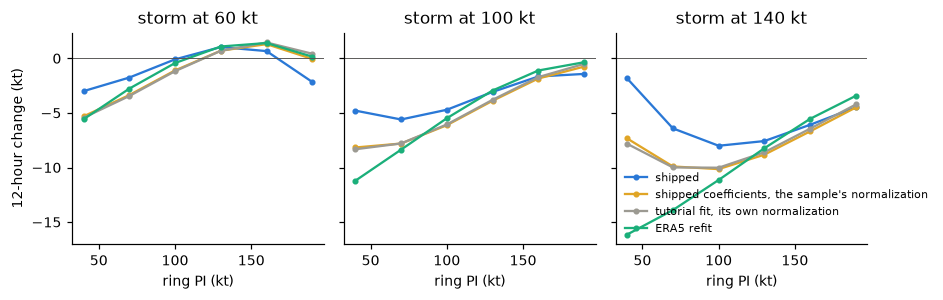

In [9]:
winds, pis = (60, 100, 140), (40, 70, 100, 130, 160, 190)
fits = {
    'shipped': shipped['w'],
    "shipped coefficients, the sample's normalization": {
        **tutorial['w'],
        'params': shipped['w']['params'],
    },
    'tutorial fit, its own normalization': tutorial['w'],
    'ERA5 refit': era5['w'],
}
resp = pd.DataFrame(
    {
        (name, wind): [
            refit.response(
                fit['params'], fit['meanX'], fit['stdX'], fit['meanY'], fit['stdY'], wind, pi
            )
            for pi in pis
        ]
        for name, fit in fits.items()
        for wind in winds
    },
    index=pd.Index(pis, name='ring PI (kt)'),
)
fig, axes = plt.subplots(1, len(winds), figsize=(9, 2.8), sharey=True)
for ax, wind in zip(axes, winds):
    for name, color in zip(fits, ('#2a78d6', '#e0a526', '#9c9a92', '#1baf7a')):
        ax.plot(pis, resp[(name, wind)], color=color, label=name, marker='o', ms=3)
    ax.axhline(0, color='#52514e', lw=0.6)
    ax.set_title(f'storm at {wind} kt')
    ax.set_xlabel('ring PI (kt)')
axes[0].set_ylabel('12-hour change (kt)')
axes[-1].legend(frameon=False, fontsize=7)
fig.tight_layout()
resp.T.round(1)

## 4. Refitting the regressions on ERA5

`ocr.risks.hurricane.refit` fits both regressions as that script does, on our ERA5 environment along the tutorial's observed tracks
of 1981–2012, and writes the normalization of its own sample. Land is read as `--land fine` reads
it; the tutorial file's fit uses its 300 km land mean. Water steps fit about as well as with the
tutorial file (R² 0.395 against 0.392), and land steps better (0.537 against 0.455).

In [10]:
pd.DataFrame(
    {
        (name, {'w': 'water', 'l': 'land'}[tag]): {
            'steps': fit[tag]['n'],
            'R2': fit[tag]['r2'],
            'rmse (kt)': fit[tag]['rmse'],
        }
        for name, fit in (('tutorial file', tutorial), ('ERA5', era5))
        for tag in 'wl'
    }
).style.format('{:.3f}')

CHAZ adds to each 12-hour step an error drawn from the regression's errors on observed steps that
start in the same 10 kt wind bin. Those errors also depend on PI. Over water at 60–100 kt, steps in the top
third of ring PI gain 2.9–3.4 kt more than predicted, and gain more than 10 kt above the prediction
in 0.21–0.22 of steps, against 0.09 in the bottom third. `--intensity refit-pi` draws the error
from steps over the same surface (water or land) in the same wind bin and tercile of ring PI,
where the bin holds enough steps to split. Lee et al. (2016) draw it by starting wind only; Lee et
al. (2015) found the errors depend most on starting wind and less on PI.

They depend on the basin too. At 64–96 kt over water, observed storms gain more than predicted by 4.1 kt
in the North Indian Ocean, 1.8 in the North Atlantic and 1.6 in the western Pacific, against 0.4 in
the Southern Hemisphere and 0.3 in the eastern Pacific. `--intensity refit-basin` draws from
the steps of the same basin as well, where the basin has enough of them. Lee et al. (2016) fit
basin-specific regressions and found no advantage over a single global one, and argue that for
climate downscaling basin-dependent tuning could add errors, since the differences between basins
may change with the climate. Both options are our additions.

In [11]:
residuals = refit.residuals_by_pi(era5).loc['w']
residuals.style.format(
    {
        'n': '{:.0f}',
        'PI median': '{:.0f}',
        'mean': '{:+.1f}',
        'sd': '{:.1f}',
        'P(> +10 kt)': '{:.2f}',
    }
).set_caption(
    'ERA5 refit, water regression: observed minus predicted 12-hour change (kt), by starting '
    'wind and tercile of ring PI'
)

In [12]:
steps = refit.predictions(era5, era5_env, meanstd.YEARS)
hurricane_steps = steps[(steps['v0'] >= 64) & (steps['v0'] < 96)]
by_basin = hurricane_steps.groupby(['regression', 'basin'])['residual']
pd.DataFrame({'steps': by_basin.size(), 'mean (kt)': by_basin.mean()}).unstack(0).style.format(
    {
        ('steps', 'w'): '{:.0f}',
        ('steps', 'l'): '{:.0f}',
        ('mean (kt)', 'w'): '{:+.1f}',
        ('mean (kt)', 'l'): '{:+.1f}',
    }
).set_caption('ERA5 refit: observed minus predicted 12-hour change at 64-96 kt, 1981-2012')

Against `--land fine` alone, the refit lifts major time in the Philippine Sea from 0.27 to 0.48 of
observed and cuts the excess north of 35°N in the western Pacific from 168 to 71 times observed at
96 kt. In the North
Atlantic it loses ground: hurricane time in the Gulf falls from 0.99 to 0.70 of observed (1.00 to
0.67 without the scaling), and US hurricane landfalls from 0.62 to 0.53 (0.62 to 0.50).

Of the three refits, refit-basin comes closest in the North Atlantic: US landfalls 0.96 of
observed, hurricane landfalls 0.64 and Gulf hurricane time 0.86. It makes more North Atlantic
storms than observed, so the scaling lowers these by 5%; without it they are 1.00, 0.67 and 0.91.
US major landfalls fall, from 0.68 of observed with `--land fine` to 0.50 (0.53 without the
scaling). In the western Pacific refit-basin brings major time in the Philippine Sea to 0.82 and
Philippine hurricane landfalls to 0.64. It overshoots in the Southern Hemisphere: major time is
2.3 times observed in the South Pacific and 1.8 times in the Australian region, as with refit-pi
(2.5 and 2.0).

In [13]:
options = ['shipped', 'fine land', 'refit', 'refit-pi', 'refit-basin']
key_rows = (
    [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)]
    + ['NA share peak >= 64 kt', 'NA share peak >= 96 kt']
    + [
        f'NA time >= {threshold}: {region}'
        for threshold in (64, 96)
        for region in validate.NA_REGIONS
    ]
    + [f'time {region} >= {threshold}' for threshold in (64, 96) for region in validate.REGIONS]
    + [
        f'landfall {country} >= 64'
        for country in ('PHL', 'CHN', 'TWN', 'JPN', 'VNM', 'MEX', 'AUS', 'IND')
    ]
)
vs_observed(key_rows, options).style.format('{:.2f}').set_caption(
    'IBTrACS per year and each option over IBTrACS, 1981-2019'
)

,IBTrACS per yr,shipped,fine land,refit,refit-pi,refit-basin
Atl+Gulf landfalls >= 34 kt,3.08,0.89,0.90,0.90,0.87,0.96
Atl+Gulf landfalls >= 64 kt,1.36,0.60,0.62,0.53,0.51,0.64
Atl+Gulf landfalls >= 96 kt,0.26,0.67,0.68,0.42,0.43,0.50
NA share peak >= 64 kt,0.51,0.91,0.92,0.81,0.78,0.95
NA share peak >= 96 kt,0.21,0.96,0.99,0.83,0.83,0.97
NA time >= 64: Gulf,10.28,0.92,0.99,0.70,0.68,0.86
NA time >= 64: Caribbean,11.97,0.64,0.65,0.67,0.71,0.80
NA time >= 64: W Atlantic,29.31,0.53,0.54,0.55,0.57,0.67
NA time >= 64: MDR,18.23,0.56,0.56,0.64,0.67,0.77
NA time >= 64: Subtropical,23.87,0.69,0.68,0.61,0.56,0.87


In [14]:
na_scaled = [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)] + [
    f'NA time >= {threshold}: {region}' for threshold in (64, 96) for region in validate.NA_REGIONS
]
sets = ['CHAZ team', *options]
scaling = rates.loc['NA TS storms/yr', 'IBTrACS'] / rates.loc['NA TS storms/yr', sets]
unscaled = (
    rates.loc[na_scaled, sets].div(scaling, axis=1).div(rates.loc[na_scaled, 'IBTrACS'], axis=0)
)
pd.concat([scaling.to_frame('scaling factor').T, unscaled]).style.format('{:.2f}').set_caption(
    'North Atlantic quantities over IBTrACS without the scaling to the observed North Atlantic '
    'storm count, 1981-2019, and the factor the scaled ratios carry'
)

,CHAZ team,shipped,fine land,refit,refit-pi,refit-basin
scaling factor,1.05,1.01,1.00,1.05,1.07,0.95
Atl+Gulf landfalls >= 34 kt,0.68,0.88,0.90,0.85,0.82,1.00
Atl+Gulf landfalls >= 64 kt,0.42,0.59,0.62,0.50,0.47,0.67
Atl+Gulf landfalls >= 96 kt,0.43,0.66,0.68,0.40,0.40,0.53
NA time >= 64: Gulf,0.60,0.91,1.00,0.67,0.64,0.91
NA time >= 64: Caribbean,0.63,0.63,0.66,0.64,0.67,0.84
NA time >= 64: W Atlantic,0.50,0.53,0.54,0.52,0.53,0.71
NA time >= 64: MDR,0.55,0.55,0.56,0.61,0.62,0.81
NA time >= 64: Subtropical,0.54,0.68,0.68,0.58,0.52,0.91
NA time >= 64: north of 45N,0.70,2.21,2.23,0.67,0.45,1.22


## 5. Lee et al. (2018)'s measures, and a test on years the fit did not see

Lee et al. (2018, section 2.4), who built CHAZ, judge it by where the observations fall among the
model's realizations of the same period. Here a realization is one track realization with one of
its 40 intensity members, over every year, so each run has 400, as their runs did; the CHAZ team's
set has 10 files of 40. The rank of a quantity is the percentage of realizations whose total over
the period is below the observed total, a tie counting half. If the observations behaved like one more realization,
their ranks would spread evenly from 0 to 100. The t statistic is the simulated mean minus the
observed mean, over a standard deviation that pools the observed years and the simulated
(realization, year) samples (their equations 1 and 2).

We apply both to the 39 counts in `validate.COUNTED`: US Atlantic and Gulf landfalls at 34, 64
and 96 kt by the first-crossing rule, time at 64 and 96 kt in five North Atlantic regions and nine
others, and hurricane landfalls in eight countries, none scaled. Which counts to use is our choice;
Emanuel (2025) also offers his metrics as an example rather than a final set. The table gives the
share of the 39 whose observed total ranks between 5 and 95, and the mean and median |t|, with landfalls counted by the first-crossing rule and, as a
sensitivity test, at each storm's strongest crossing and last offshore wind.

In [15]:
PERIODS = {'1981-2019': range(1981, 2020), '2000-2019': range(2000, 2020)}
RULES = {
    'first crossing (Emanuel 2025)': validate.COUNTED,
    'strongest crossing, last offshore wind': validate.COUNTED_OFFSHORE,
}
measures = {}
for rule, counted in RULES.items():
    for period, years in PERIODS.items():
        for name, run_realizations in realizations.items():
            lee = skill.lee(run_realizations, tables['IBTrACS'], counted, years)
            measures[(rule, period, name)] = {
                'share within 5-95%': skill.in_band(lee['rank']),
                'mean |t|': skill.mean_abs_t(lee['t']),
                'median |t|': lee['t'].abs().median(),
            }
measures = pd.DataFrame(measures).T
measures.style.format('{:.3f}').set_caption(
    f'Lee et al. (2018) over the {len(validate.COUNTED)} counts: the share whose observed total '
    'lies within the 5th-95th percentile range of the 400 realizations, and the mean and median |t|'
)

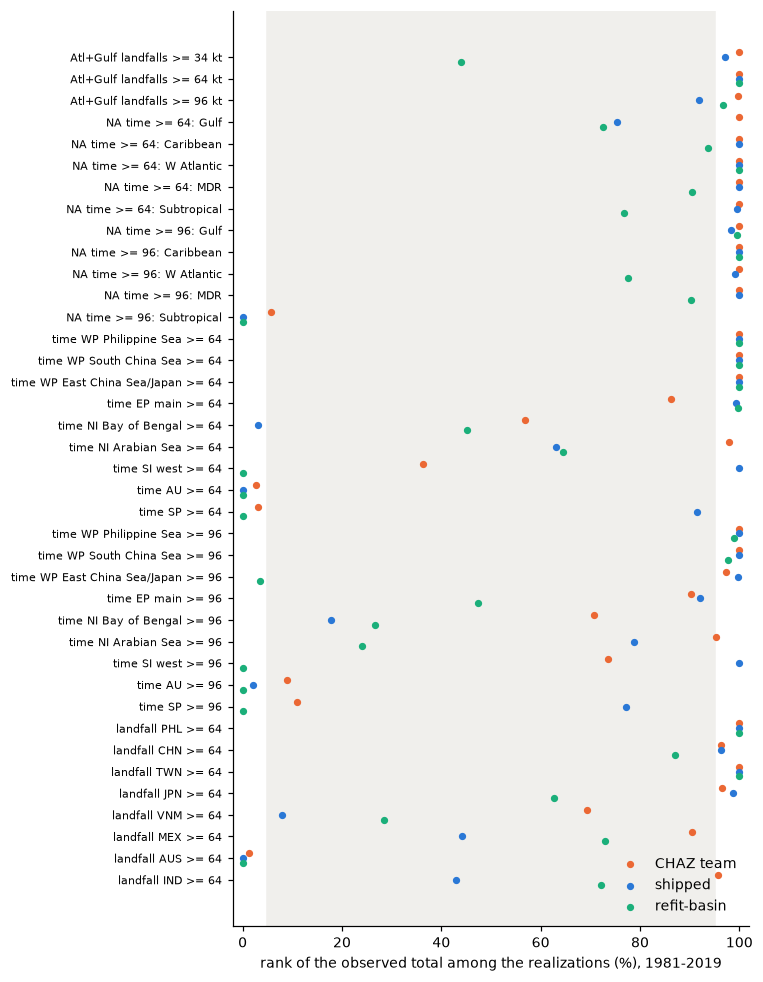

In [16]:
lee_all = {
    name: skill.lee(realizations[name], tables['IBTrACS'], validate.COUNTED, PERIODS['1981-2019'])
    for name in ('CHAZ team', 'shipped', 'refit-basin')
}
fig, ax = plt.subplots(figsize=(7, 9))
rows_y = np.arange(len(validate.COUNTED))
ax.axvspan(5, 95, color='#f0efec', zorder=0)
for offset, (name, lee) in enumerate(lee_all.items()):
    ax.scatter(lee['rank'], rows_y + (offset - 1) * 0.22, s=14, color=COLORS[name], label=name)
ax.set_yticks(rows_y, validate.COUNTED, fontsize=7)
ax.invert_yaxis()
ax.set(xlim=(-2, 102), xlabel='rank of the observed total among the realizations (%), 1981-2019')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()

Over 1981–2019 the observed total ranks between 5 and 95 for 0.282 of the counts with the shipped
run, 0.333 with `--land fine` and with refit, and 0.436 with refit-basin, and for 0.282 with the
CHAZ team's set. The mean |t| is 0.600 for the shipped run, 0.575 with `--land fine`, 0.464 with
refit and 0.355 with refit-basin. The figure shows the rank of each count for the CHAZ team's set,
the shipped run and refit-basin.

The refits are fit on the observed tracks of 1981–2012, so 1981–2019 is partly in sample for them.
`--fit 1981-1999` fits refit and refit-basin on 1981–1999 only, the training years of Lee et al.
(2016), so 2000–2019 tests them on years neither fit saw. Before running that test we set a rule
for choosing between them: refit-basin would replace plain refit only if more of the 39 counts
ranked between 5 and 95 over 2000–2019 and the 5th percentile of the paired difference over 2,000
resamples of whole years stayed above zero. We stated the rule before running the test; the commit
that first records it also holds the results. The resamples use the same years for every run. The table also gives the mean |t|, which
we added after seeing the result of the rule: once with each run's own spread, as Lee et al.
define t, and once with every run's difference of means divided by the shipped run's simulated spread, so
that a run cannot lower its |t| by spreading its realizations wider.

In [17]:
held_out = {
    name: realizations[name]
    for name in ('shipped', 'fine land', 'refit, fit 1981-1999', 'refit-basin, fit 1981-1999')
}
pairs = [
    ('refit-basin, fit 1981-1999', 'refit, fit 1981-1999'),
    ('refit-basin, fit 1981-1999', 'shipped'),
    ('refit, fit 1981-1999', 'shipped'),
    ('fine land', 'shipped'),
]
STATISTICS = {
    'share within 5-95% (the declared rule)': {'statistic': 'in band'},
    "mean |t|, each run's own spread": {'statistic': 'mean |t|'},
    "mean |t|, the shipped run's spread": {
        'statistic': 'mean |t|',
        'scale': realizations['shipped'],
    },
}
rows = {}
for label, options in STATISTICS.items():
    resampled = skill.bootstrap(
        held_out,
        tables['IBTrACS'],
        validate.COUNTED,
        PERIODS['2000-2019'],
        n=2000,
        seed=0,
        **options,
    )
    for first, second in pairs:
        difference = resampled[first] - resampled[second]
        rows[(label, f'{first} − {second}')] = {
            'median': difference.median(),
            '5%': difference.quantile(0.05),
            '95%': difference.quantile(0.95),
            'P(first better)': (difference > 0).mean()
            if label.startswith('share')
            else (difference < 0).mean(),
        }
pd.DataFrame(rows).T.style.format('{:+.3f}').set_caption(
    'Paired differences over 2,000 resamples of the years 2000-2019, the same years for every run; '
    'the share is better higher, mean |t| lower'
)

**The declared rule.** Over 2000–2019, with the fits on 1981–1999, 0.564 of the counts rank between 5
and 95 with refit-basin and 0.359 with plain refit, against 0.385 with `--land fine` and 0.333
with the shipped run. Refit-basin's lead over plain refit is +0.077 at the median of the
resamples, with a 5th percentile of −0.026, so by the rule refit-basin does not replace plain
refit. Plain refit does no better than the shipped run by this measure (+0.026, with 90% of
resamples between −0.077 and +0.128), nor does `--land fine` (+0.000). One count is 0.026 of the
share. Every run has well under the 0.90 a perfectly calibrated set would have, and the share counts a near
miss and a large miss alike, so it separates the runs weakly.

**Lee et al.'s t.** The mean |t| keeps the size of each miss. Over 2000–2019 it
is 0.638 for the shipped run, 0.618 with `--land fine`, 0.506 with plain refit and 0.364 with
refit-basin, and every paired difference in the table lies on one side of zero: refit-basin −
plain refit −0.131 (−0.191 to −0.066), plain refit − shipped −0.125 (−0.175 to −0.073). With the
shipped run's spread as the common scale the differences shrink but keep their sign (refit-basin −
plain refit −0.062, −0.116 to −0.003; plain refit − shipped −0.094, −0.145 to −0.043). The median |t| does not agree for plain
refit: 0.517 against 0.419 for the shipped run. Lee et al. read t count by count; averaging |t|
over our 39 counts is our own summary, and the choice of counts is ours too.

**Other normalizations.** We read the shipped coefficients three other ways: with
`observed_data.nc` (`--normalization training`), with a normalization built from our ERA5 along the
observed tracks (`port`), and with the tutorial's normalization whose environment entries are taken
from that ERA5 sample (`env`). Over 2000–2019 these lower the mean |t| to 0.551, 0.528 and 0.577,
but raise the median to 0.514, 0.474 and 0.491. The share of counts ranked between 5 and 95 is
0.333 with `training`, as with the shipped run, and 0.308 with the other two. Section 6 shows what
they change. Of our runs, `training` comes closest to the CHAZ team's set, which has a mean |t| of
0.547 over these years ([tracks.ipynb](tracks.ipynb), section 5).

**Settings for our runs.** Our ERA5 runs use the public code's settings. Its intensity model is the published
one of Lee et al. (2016), it is what Meiler et al. (2026) use for the hazard maps we compare
against, and it is what the climate-model runs keep, as Lee et al. (2020) and Fosu et al. (2024)
do. The refits fit better by the mean |t|, but plain refit's median |t| is worse, the measure that
favours them was chosen after the declared rule failed, and refit-basin draws its errors by basin,
where Lee et al. (2016) found basin-specific regressions no better than a global one and warned
that basin tuning could add errors under climate change. Refit-basin is kept as a tested option.

The test on 2000–2019 has limits. The seeding ratio counts the observed storms of 1981–2005, which
include 2000–2005. Our run also makes more storms in 2000–2019 than in 1981–1999, while the
observed count stays level ([landfall-weights.ipynb](landfall-weights.ipynb), section 4). And we
chose which options to compare after looking at all of 1981–2019. Last, the refits learn from the
tutorial's observed-track file (`bt_global_predictors.nc`) and are tested against IBTrACS as we
read it, so where the two records differ, the difference may affect the refits' results.

## 6. Misses that remain

No option fixes every miss. With the shipped run:

- High latitudes: hurricane time is 13.21 times observed south of 30°S and 7.41 times north of
  35°N in the western Pacific. Refit-basin lowers these to 5.31 and 3.42, and the other
  normalizations to 10.10 and 5.81 (training), 9.26 and 5.96 (port) and 5.77 and 5.29 (env). The
  CHAZ team's set has 5.89 and 4.29.
- Major time in the Philippine Sea is 0.27 of observed; refit-basin raises it to 0.82, the other
  normalizations to between 0.34 and 0.47, and the CHAZ team's set has 0.40.
- US hurricane landfalls are 0.60 of observed. The other normalizations lower them (0.45 with
  training, 0.44 with port, 0.56 with env), as low as the CHAZ team's 0.45, and refit-basin raises
  them a little (0.64).
- In the South Pacific the shipped run is close at major strength (0.90); refit-basin makes 1.93
  times the observed storms reaching 34 kt there and 2.30 times the major time.
- Taiwan's hurricane landfalls are 0.39 of observed with the shipped run and about 0.5 with the
  others.

In [18]:
left = (
    [
        f'TS formed {region}'
        for region in ('SP', 'AU', 'SI west', 'SH south of 30S', 'WP north of 35N')
    ]
    + ['time SP >= 96', 'time AU >= 96', 'time SH south of 30S >= 64', 'time WP north of 35N >= 64']
    + ['NA time >= 96: Subtropical', 'NA time >= 96: north of 45N', 'NA time >= 96: Gulf']
    + ['time WP Philippine Sea >= 96']
    + ['landfall TWN >= 64', 'Atl+Gulf landfalls >= 64 kt', 'Atl+Gulf landfalls >= 96 kt']
)
vs_observed(
    left,
    [
        'CHAZ team',
        'shipped',
        'shipped, training normalization',
        'shipped, port normalization',
        'shipped, env normalization',
        'refit-basin',
    ],
).style.format('{:.2f}')

,IBTrACS per yr,CHAZ team,shipped,"shipped, training normalization","shipped, port normalization","shipped, env normalization",refit-basin
TS formed SP,6.74,1.66,1.33,1.86,1.74,1.62,1.93
TS formed AU,10.69,0.91,1.04,1.15,1.12,1.16,1.20
TS formed SI west,9.56,1.16,1.03,1.23,1.20,1.19,1.26
TS formed SH south of 30S,0.08,5.16,13.23,7.38,7.58,6.17,6.92
TS formed WP north of 35N,0.08,6.58,12.51,7.83,6.25,8.27,4.91
time SP >= 96,13.10,1.22,0.90,1.45,1.41,1.04,2.30
time AU >= 96,12.69,1.20,1.34,1.43,1.46,1.28,1.81
time SH south of 30S >= 64,1.97,5.89,13.21,10.10,9.26,5.77,5.31
time WP north of 35N >= 64,4.00,4.29,7.41,5.81,5.96,5.29,3.42
NA time >= 96: Subtropical,1.69,1.82,2.62,1.92,2.28,1.29,2.81


## Summary

| | chosen | evidence |
| --- | --- | --- |
| land term | the public code's: the 2° mask cell the storm is in | section 5: `--land fine` changes little (held-out mean \|t\| 0.618 against 0.638; paired median difference in the share +0.000) |
| intensity | the public code's: Lee et al. (2016)'s model, error drawn by starting wind | sections 3–5: the published model, used for Meiler et al.'s maps and kept on climate models; the refits lower the held-out mean \|t\| (0.506, 0.364), but refit-basin failed the rule set beforehand and plain refit's median \|t\| is worse (0.517 against 0.419) |

What the public settings leave: too little time at major strength in the Philippine Sea, far too
much hurricane time at high latitudes, and too few US hurricane landfalls (section 6).

Open:

- **The normalization.** The public code reads the tutorial's `coefficient_meanstd.nc`, which is not
  the normalization the shipped coefficients were fit with. Read with that one (`observed_data.nc`,
  `--normalization training`), our run comes close to the CHAZ team's set in the North Atlantic
  ([tracks.ipynb](tracks.ipynb), section 5) and moves toward it elsewhere (section 6). Which file
  our runs should read is a question for the CHAZ team ([overview.md](overview.md)).
- **Refit-basin.** Of the four options in the held-out test it leads on every summary in section 5,
  but it failed the rule we set before that test, and its error sampling is our addition, which
  Lee et al. (2016)'s warning about basin tuning gives reason to treat with caution. Test it again
  only with a test declared in advance and run on new evidence, such as the coastal winds of the
  hazard maps, or after the CHAZ team answers our questions on error sampling
  ([overview.md](overview.md)).
- **A regional calibration.** No option here fixes the high latitudes or US hurricane landfalls,
  and the refits add an overshoot in the Southern Hemisphere. A genesis
  calibration would come first. `chaz --genesis calibrated` scales TCGI by region, but its map was fit on an earlier run
  and needs refitting on the configuration chosen here. A regional adjustment of intensity would
  come after it.
- **Climate-model runs.** The refits are fit on ERA5 and run only on ERA5 forcing. A climate model
  would need its own normalization of the refit regressions, as it does for the shipped ones
  ([cmip.ipynb](cmip.ipynb)).